# 04 · Calibration, triage threshold, fusion, and out-of-distribution detector
Everything here is fit on the **validation** split (images the CNN never trained on).
The test split is not touched until notebook 06.

1. Temperature scaling: one scalar `T`, `softmax(logits / T)`.
2. Triage threshold `τ`: highest value with urgent sensitivity ≥ 0.90 on validation.
3. Fusion: XGBoost on [7 calibrated CNN probs, age, sex, site], evaluated with 5-fold
   lesion-grouped CV *within* validation and compared against the CNN alone.
4. OOD detector: Mahalanobis distance of the CNN embedding + low max-softmax confidence.

In [1]:
import sys; sys.path.insert(0, "..")
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from src.data import CLASSES, FITZ_TO_HAM, load_metadata, IMG_SIZE
from src.fusion import fusion_features, make_xgb
from src.metrics import (all_metrics, ece, is_urgent, p_urgent, reliability_curve,
                         sens_spec, threshold_for_sensitivity)
from src.model import fit_temperature, get_device, load_model, logits_and_embeddings, softmax_np
from src.data import to_model_input

plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})
out = np.load("../models/outputs.npz", allow_pickle=True)
df = load_metadata("../data/ham").set_index("image_id")
val = df.loc[out["val_ids"]]
y_val = val["y"].to_numpy()
print({k: out[k].shape for k in out.files if k.endswith("logits")})
print(json.load(open("../models/train_log.json"))["best_val_bacc"])

{'train_logits': (7009, 7), 'val_logits': (1503, 7), 'test_logits': (1503, 7), 'fitz_logits': (1916, 7)}
0.6757136129558395


## 1 · Temperature scaling

/kaggle/working/proj/notebooks/../src/model.py:53: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  return float(log_t.exp())


T = 1.466  |  val ECE before 0.0648 -> after 0.0243


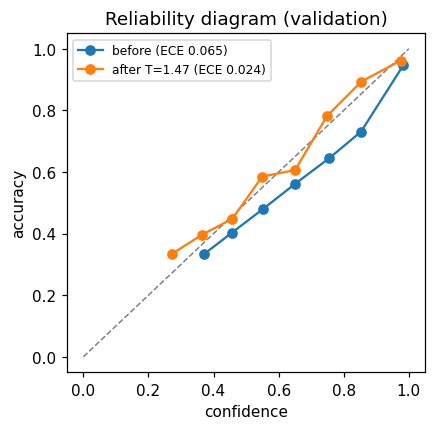

In [2]:
T = fit_temperature(out["val_logits"], y_val)
p_raw, p_cal = softmax_np(out["val_logits"]), softmax_np(out["val_logits"], T)
print(f"T = {T:.3f}  |  val ECE before {ece(p_raw, y_val):.4f} -> after {ece(p_cal, y_val):.4f}")

fig, ax = plt.subplots(figsize=(4.2, 4))
ax.plot([0, 1], [0, 1], ls="--", c="gray", lw=1)
for p, lab in [(p_raw, f"before (ECE {ece(p_raw, y_val):.3f})"), (p_cal, f"after T={T:.2f} (ECE {ece(p_cal, y_val):.3f})")]:
    x, y, _ = reliability_curve(p, y_val)
    ax.plot(x, y, "o-", label=lab)
ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.legend(fontsize=8)
ax.set_title("Reliability diagram (validation)")
fig.savefig("../figures/reliability.png")

## 2 · Triage threshold τ (sensitivity ≥ 0.90 on validation)

In [3]:
yu_val, s_val = is_urgent(y_val), p_urgent(p_cal)
tau = threshold_for_sensitivity(yu_val, s_val, 0.90)
print(f"tau = {tau:.4f}", "val sens/spec =", np.round(sens_spec(yu_val, s_val, tau), 3))
pd.Series(all_metrics(p_cal, y_val, tau)).round(3)

tau = 0.1476 val sens/spec = [0.901 0.7  ]


sensitivity_urgent    0.901
specificity_urgent    0.700
auroc_urgent          0.897
balanced_accuracy     0.676
ece                   0.024
dtype: float64

## 3 · Fusion with metadata
The validation split is the only data with CNN predictions on unseen images, so fusion is
tuned/evaluated with 5-fold **lesion-grouped** CV inside it. Out-of-fold predictions give a
fair CNN-alone vs. CNN+metadata comparison. A null result is a valid result.

In [4]:
X_val = fusion_features(p_cal, val.reset_index())
# Same 1/sqrt(class_freq) weighting as the CNN, so the comparison is like for like.
from src.train import class_weights
w_val = class_weights(y_val).numpy()[y_val]
oof = np.zeros_like(p_cal)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
for tr, te in sgkf.split(X_val, y_val, groups=val["lesion_id"]):
    m = make_xgb().fit(X_val.iloc[tr], y_val[tr], sample_weight=w_val[tr])
    oof[te] = m.predict_proba(X_val.iloc[te])

tau_fusion = threshold_for_sensitivity(yu_val, p_urgent(oof), 0.90)
cmp = pd.DataFrame({
    "CNN alone": all_metrics(p_cal, y_val, tau),
    "CNN + metadata (OOF)": all_metrics(oof, y_val, tau_fusion),
}).round(3)
cmp

,CNN alone,CNN + metadata (OOF)
sensitivity_urgent,0.901,0.901
specificity_urgent,0.700,0.706
auroc_urgent,0.897,0.892
balanced_accuracy,0.676,0.595
ece,0.024,0.046


**Decision rule, fixed before looking at test:** use fusion for the triage decision only if
it improves urgent AUROC by ≥ 0.005 *and* specificity at 90% sensitivity, without lowering
balanced accuracy. Otherwise the CNN makes the decision and fusion is kept to *explain*
how metadata shifts the score.

In [5]:
d = cmp["CNN + metadata (OOF)"] - cmp["CNN alone"]
use_fusion = bool(d["auroc_urgent"] >= 0.005 and d["specificity_urgent"] > 0 and d["balanced_accuracy"] >= 0)
print("use_fusion =", use_fusion, d.round(3).to_dict())

xgb = make_xgb().fit(X_val, y_val, sample_weight=w_val)
xgb.save_model("../models/xgb.json")
X_val.sample(100, random_state=0).to_csv("../models/fusion_background.csv", index=False)
np.save("../results/val_oof_fusion.npy", oof)

use_fusion = False {'sensitivity_urgent': 0.0, 'specificity_urgent': 0.006, 'auroc_urgent': -0.005, 'balanced_accuracy': -0.081, 'ece': 0.022}


## 4 · Out-of-distribution detector
A phone photo or a cat is not a dermoscopy image. Two scores on the 1280-d CNN embedding,
each thresholded at its 99th percentile on validation (so each flags ~1% of real images):
- **kNN distance** (Sun et al., 2022): cosine distance to the 10th-nearest *train* embedding.
- **Mahalanobis distance** to the nearest class mean (shared, Ledoit-Wolf covariance).

Either one alone missed several non-skin images in development: the fine-tuned embedding
maps many natural photos close to lesions (kNN misses flat images, Mahalanobis misses
textured ones), so an image is flagged if *either* score is out of range.
A separate "low confidence" badge uses max softmax probability (10th percentile on validation).

In [6]:
from sklearn.covariance import LedoitWolf
from src.triage import OODDetector

emb_tr = out["train_emb"].astype(np.float64)
y_tr = df.loc[out["train_ids"], "y"].to_numpy()
means = np.stack([emb_tr[y_tr == k].mean(0) for k in range(7)])
precision = LedoitWolf().fit(emb_tr - means[y_tr]).precision_
bank = (emb_tr / np.linalg.norm(emb_tr, axis=1, keepdims=True)).astype(np.float32)

det = OODDetector(means, precision, bank, np.inf, np.inf, 0.0)
d_val, k_val = det.distance(out["val_emb"].astype(np.float64)), det.knn(out["val_emb"].astype(np.float64))
maha_thr, knn_thr = float(np.percentile(d_val, 99)), float(np.percentile(k_val, 99))
msp_thr = float(np.percentile(p_cal.max(1), 10))
val_flag_rate = float(((d_val > maha_thr) | (k_val > knn_thr)).mean())
print(f"maha thr {maha_thr:.1f}, kNN thr {knn_thr:.3f}, msp thr {msp_thr:.3f}; "
      f"validation images flagged by either: {val_flag_rate:.1%}")
np.savez("../models/ood.npz", means=means, precision=precision, bank=bank, maha_threshold=maha_thr,
         knn_threshold=knn_thr, msp_threshold=msp_thr)

maha thr 3460.8, kNN thr 0.687, msp thr 0.485; validation images flagged by either: 2.1%


### Test the detector on images that are clearly not dermoscopy
Stock photos bundled with scikit-image (a cat, a person, coffee, a rocket, bricks…), plus
a blank wall, pure noise, and a skin-coloured flat image. They must all be flagged.

In [7]:
from skimage import data as skd

def to01(a):
    a = np.asarray(a)
    if a.ndim == 2:
        a = np.repeat(a[..., None], 3, -1)
    a = Image.fromarray(a[..., :3].astype(np.uint8)).resize((IMG_SIZE, IMG_SIZE))
    return np.asarray(a, dtype=np.float32) / 255

rng = np.random.default_rng(0)
ood_imgs = {
    "cat": skd.chelsea(), "astronaut": skd.astronaut(), "coffee": skd.coffee(),
    "rocket": skd.rocket(), "bricks": skd.brick(), "camera man": skd.camera(),
    "grass": skd.grass(), "hubble": skd.hubble_deep_field(),
    "blank wall": np.full((300, 300, 3), (225, 220, 210), np.uint8),
    "noise": rng.integers(0, 255, (300, 300, 3), dtype=np.uint8),
    "flat skin tone": np.full((300, 300, 3), (224, 172, 150), np.uint8),
    "black": np.zeros((300, 300, 3), np.uint8),
}
device = get_device()
model = load_model("../models/cnn.pt", device)
X = to_model_input(np.stack([to01(v) for v in ood_imgs.values()])).to(device)
lg, em = logits_and_embeddings(model, X)
pr = softmax_np(lg.cpu().numpy(), T)
det = OODDetector(means, precision, bank, maha_thr, knn_thr, msp_thr)
f = det.flags(em.cpu().numpy().astype(np.float64), pr)
ood_table = pd.DataFrame({"maha": f["maha"].round(0), "knn": f["knn"].round(3),
                          "flag_unlike_training": f["unlike_training"],
                          "max_softmax": pr.max(1).round(2), "flag_low_conf": f["low_confidence"],
                          "would_triage": np.where(p_urgent(pr) >= tau, "urgent", "benign")},
                         index=list(ood_imgs))
ood_table

,maha,knn,flag_unlike_training,max_softmax,flag_low_conf,would_triage
cat,1.637000e+03,0.723,True,0.67,False,urgent
astronaut,2.015000e+03,0.703,True,0.32,True,urgent
coffee,2.034000e+03,0.730,True,0.61,False,benign
rocket,1.870000e+03,0.696,True,0.42,True,benign
bricks,3.275000e+03,0.834,True,0.63,False,benign
camera man,2.733000e+03,0.704,True,0.74,False,benign
grass,2.012000e+03,0.714,True,0.53,False,benign
hubble,2.177000e+03,0.715,True,0.65,False,urgent
blank wall,2.953217e+07,0.612,True,1.00,False,benign
noise,1.615000e+03,0.764,True,0.36,True,benign


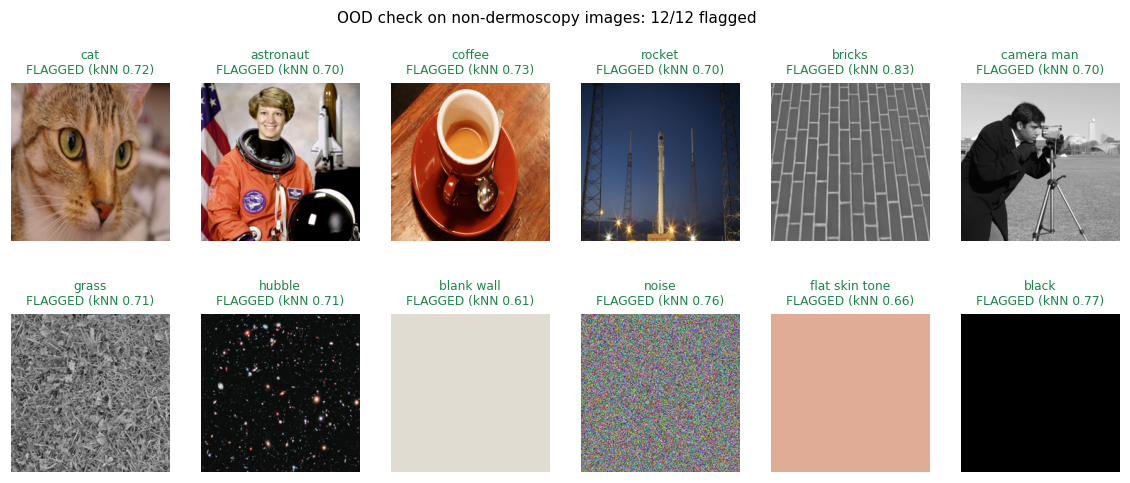

In [8]:
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, (name, img), (_, r) in zip(axes.flat, ood_imgs.items(), ood_table.iterrows()):
    ax.imshow(to01(img)); ax.axis("off")
    ax.set_title(f"{name}\n{'FLAGGED' if r.flag_unlike_training else 'not flagged'} (kNN {r.knn:.2f})",
                 fontsize=8, color="#1e8449" if r.flag_unlike_training else "#c0392b")
fig.suptitle(f"OOD check on non-dermoscopy images: {int(ood_table.flag_unlike_training.sum())}/{len(ood_table)} flagged", fontsize=10)
fig.savefig("../figures/ood_examples.png")

**Caveat:** the kNN + Mahalanobis combination was chosen *after* Mahalanobis alone failed on
the images above, so they are not a clean test. Below is a second set of non-dermoscopy
images that played no part in designing the detector (thresholds unchanged).

In [9]:
fresh = {"coins": skd.coins(), "moon": skd.moon(), "page of text": skd.page(), "horse": skd.horse().astype(np.uint8) * 255,
         "histology (IHC)": skd.immunohistochemistry(), "retina": skd.retina(), "colour wheel": skd.colorwheel(),
         "logo": skd.logo(), "clock": skd.clock(), "motorcycle": skd.stereo_motorcycle()[0]}
Xf = to_model_input(np.stack([to01(v) for v in fresh.values()])).to(device)
lgf, emf = logits_and_embeddings(model, Xf)
ff = det.flags(emf.cpu().numpy().astype(np.float64), softmax_np(lgf.cpu().numpy(), T))
fresh_table = pd.DataFrame({"knn": ff["knn"].round(3), "maha": ff["maha"].round(0),
                            "flag_unlike_training": ff["unlike_training"]}, index=list(fresh))
print(f"fresh non-dermoscopy images flagged: {int(ff['unlike_training'].sum())}/{len(fresh)}")
fresh_table

fresh non-dermoscopy images flagged: 9/10


,knn,maha,flag_unlike_training
coins,0.739,4167.0,True
moon,0.706,2045.0,True
page of text,0.738,1571.0,True
horse,0.866,2310.0,True
histology (IHC),0.707,2355.0,True
retina,0.649,2697.0,False
colour wheel,0.744,2742.0,True
logo,0.676,4864.0,True
clock,0.834,4311.0,True
motorcycle,0.716,2961.0,True


Fitzpatrick17k clinical photos flagged as unlike training: 24.6%


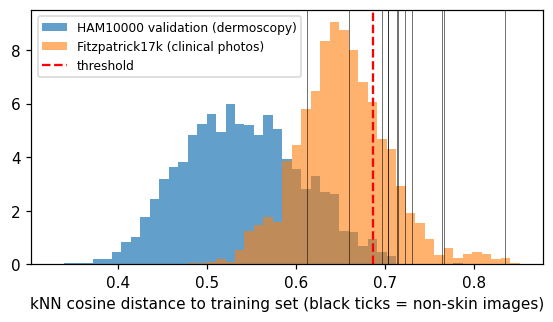

In [10]:
fz_emb = out["fitz_emb"].astype(np.float64)
fz_flag = det.flags(fz_emb, softmax_np(out["fitz_logits"], T))["unlike_training"]
fig, ax = plt.subplots(figsize=(6, 3))
bins = np.linspace(min(k_val.min(), f["knn"].min()) * .95, max(k_val.max(), f["knn"].max()) * 1.02, 50)
ax.hist(k_val, bins=bins, alpha=.7, label="HAM10000 validation (dermoscopy)", density=True)
ax.hist(det.knn(fz_emb), bins=bins, alpha=.6, label="Fitzpatrick17k (clinical photos)", density=True)
for v in f["knn"]:
    ax.axvline(v, color="k", lw=.6, alpha=.6)
ax.axvline(knn_thr, color="r", ls="--", label="threshold")
ax.set_xlabel("kNN cosine distance to training set (black ticks = non-skin images)"); ax.legend(fontsize=8)
fig.savefig("../figures/ood_distances.png")
print(f"Fitzpatrick17k clinical photos flagged as unlike training: {fz_flag.mean():.1%}")

In [11]:
cfg = {"T": T, "tau": tau, "tau_fusion": tau_fusion, "use_fusion": use_fusion,
       "maha_threshold": maha_thr, "knn_threshold": knn_thr, "msp_threshold": msp_thr}
if use_fusion:
    cfg["tau"] = tau_fusion  # the pipeline thresholds whichever probabilities it uses
cfg["tau_cnn"] = tau
json.dump(cfg, open("../models/config.json", "w"), indent=2)
json.dump({"val_comparison": cmp.to_dict(), "ood_nonskin": ood_table.reset_index().to_dict("records"),
           "ood_fresh": fresh_table.reset_index().to_dict("records"),
           "fitz_flagged_frac": float(fz_flag.mean()), "val_flagged_frac": val_flag_rate,
           "ece_val_before": ece(p_raw, y_val), "ece_val_after": ece(p_cal, y_val)},
          open("../results/calibration_fusion.json", "w"), indent=2, default=str)
cfg

{'T': 1.4663488108953444,
 'tau': 0.14763352274894714,
 'tau_fusion': 0.12058751285076141,
 'use_fusion': False,
 'maha_threshold': 3460.8204274623695,
 'knn_threshold': 0.6869912147521973,
 'msp_threshold': 0.48458728194236755,
 'tau_cnn': 0.14763352274894714}